In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


In [10]:
data=pd.read_csv(r"D:\HOPEAI\ML Resources\Machine Learning-Classification\Week4.0-Machine Learning-Classification\CLassification\1.Traditional Way\Social_Network_Ads.csv")

In [11]:
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [12]:
data["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [13]:
data=pd.get_dummies(data,columns=["Gender"],drop_first=True,dtype=int)

In [14]:
data.head()

,User ID,Age,EstimatedSalary,Purchased,Gender_Male
0,15624510,19,19000,0,1
1,15810944,35,20000,0,1
2,15668575,26,43000,0,0
3,15603246,27,57000,0,0
4,15804002,19,76000,0,1


In [15]:
X=data.drop(columns=["Purchased","User ID"],axis=1)

In [16]:
y=data["Purchased"]

In [17]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [18]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [19]:
lr_grid=LogisticRegression()
lr_grid.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [40]:
from sklearn.model_selection import GridSearchCV

param_grid={"solver":["lbfgs","liblinear","newton-cg","newton-cholesky","sag","saga"],"penalty":["l1","l2","elasticnet"]}
grid=GridSearchCV(LogisticRegression(),param_grid,refit=True,verbose=3,n_jobs=-1,scoring="f1_weighted")
grid.fit(X_train,y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


C:\Users\yasod\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
50 fits failed out of a total of 90.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\yasod\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\yasod\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\yasod\AppData\Local\Programs\Python\Python310\lib\site-packages

,estimator,LogisticRegression()
,param_grid,"{'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs', 'liblinear', ...]}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l1'


In [24]:
y_pred=grid.predict(X_test)
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0], dtype=int64)

In [25]:
from sklearn.metrics import classification_report,confusion_matrix

report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.83      0.97      0.89        73
           1       0.94      0.68      0.79        47

    accuracy                           0.86       120
   macro avg       0.88      0.83      0.84       120
weighted avg       0.87      0.86      0.85       120



In [26]:
cm=confusion_matrix(y_test,y_pred)

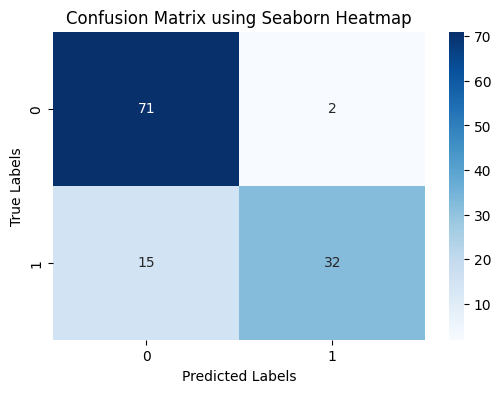

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(cm, 
    annot=True,            # Show the numbers inside the blocks
    fmt='d',               # Print numbers as integers 
    cmap='Blues',   )       # Colormap style
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix using Seaborn Heatmap')
plt.show()


In [34]:
y_prob=grid.predict_proba(X_test)[:,1]

In [36]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_test,y_prob)

0.9591955698047216